# H2: Comprehensive Project — Implementation & Review

**FIT1061 Introduction to Artificial Intelligence — HD Task 2**

H1 defined the problem and justified the approach. H2 is where you build, evaluate, and review. Implement the system you scoped in H1, run honest experiments, and write up what worked, what didn't, and what you'd do differently. H3 then defends the full arc in the W14 interview.

> **Prerequisite:** H1 (Complete). Re-read your H1 problem definition before starting.

> **No milestone discussion at H2.** H1 had the discussion; H3 (W14 interview) defends this work.

> H2 should adapt course techniques to a meaningful problem with more depth than a straightforward earlier task. Optional D4 Coin Clash enrichment is available in OnTrack but is not an assessment benchmark or prerequisite.

---

## Recap from H1: what you committed to

Paste (or rewrite in your own words) your H1 problem definition and scope contract here. This anchors H2: the implementation, experiments, and report that follow must deliver against this scope. If you've pivoted since H1, note the pivot and the reason; your tutor will read this before the H3 interview.

**Problem (from H1):** * My project uses A* search to match DNA sequences across three simulated generations of bacteria.

Set A contains five original DNA fragments from E. coli, representing the first generation. I mutate these sequences to create Set B (second generation), then mutate Set B again to create Set C (third generation).

I combine and shuffle the sequences from Sets B and C. My program compares each sample against the five original sequences in Set A and predicts which original it came from using the minimum edit distance.

I want to investigate whether DNA sequences become harder to match to their original source after more generations of mutations.*

**Technique(s) (from H1):** *I use standard A* with three heuristics: zero, remaining-length difference and base-count difference.

I also use Weighted A* with a weight of 1.5 to see whether it can explore fewer states than standard A*.

I use the Python Levenshtein library to check whether A* finds the correct minimum edit distance.*

**Data (from H1):** * I use 45 real DNA fragments from the E. coli K-12 MG1655 reference genome, with lengths of 30, 60 and 100 bases.

For each length, I have three subgroups of five original DNA sequences.

I use Python to create two simulated generations of mutations. Set B is created from Set A, and Set C is created from Set B. I test mutation rates of 5%, 15% and 30%, using substitution-only and mixed mutations (substitutions, insertions and deletions).

The original DNA comes from a real bacterial genome, but Sets B and C are artificially generated. They do not represent real bacterial samples collected across generations.*

**What makes this HD-level (from H1):** * This project goes beyond a basic A* search task because it compares two sets of DNA sequences instead of finding a path in a simple graph. It uses three different heuristics and Weighted A* to investigate which method explores fewer states and whether the results are always correct. I also use levenshtein distance to check the edit distances and run experiments with different sequence lengths, mutation rates and types of mutations.*

**Pivot since H1 (if any):** * In my original H1 plan, I generated Set B directly from Set A and matched the five modified samples against their original references.

After feedback from my tutor, I decided to make the matching problem more challenging by adding a third generation. I now mutate Set B to create Set C and combine both generations before matching them against Set A.

This allows me to test whether additional mutations make it harder to identify the original DNA sequence, while keeping the main A* approach from H1.

I also changed my verification method. Instead of writing my own dynamic-programming Levenshtein algorithm, I use the Python Levenshtein library to check my A* results.*

In [1]:
# --- SETUP ---
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

# Add your imports here
import random
import time
import Levenshtein
from d1_helpers import PriorityQueue, _reconstruct
BASES = "ATCG"
print("Setup OK.")

Setup OK.


### Data

**Original Baceteria DNA**

I use DNA fragments from the E. coli K-12 MG1655 reference genome (NCBI accession NC_000913.3).

I copied a continuous section of the FASTA sequence into my notebook. I then divided it into 45 consecutive, non-overlapping fragments with lengths of 30, 60 and 100 bases.

For each length, I created three subgroups containing five reference sequences each, giving nine groups in total.

These original fragments form Set A, representing the first simulated generation of bacteria. Later, I will mutate them to create Set B (second generation), then mutate Set B again to create Set C (third generation).

The original fragments come from a real bacterial genome, but the later generations will be generated artificially using Python.

In [2]:
# --- DATA ---

# --- YOUR CODE HERE ---
# A continuous base section from NCBI FASTA.
DNA_TEXT = (
    """AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAGAGTGTCTGATAGCAGC
TTCTGAACTGGTTACCTGCCGTGAGTAAATTAAAATTTTATTGACTTAGGTCACTAAATACTTTAACCAA
TATAGGCATAGCGCACAGACAGATAAAAATTACAGAGTACACAACATCCATGAAACGCATTAGCACCACC
ATTACCACCACCATCACCATTACCACAGGTAACGGTGCGGGCTGACGCGTACAGGAAACACAGAAAAAAG
CCCGCACCTGACAGTGCGGGCTTTTTTTTTCGACCAAAGGTAACGAGGTAACAACCATGCGAGTGTTGAA
GTTCGGCGGTACATCAGTGGCAAATGCAGAACGTTTTCTGCGTGTTGCCGATATTCTGGAAAGCAATGCC
AGGCAGGGGCAGGTGGCCACCGTCCTCTCTGCCCCCGCCAAAATCACCAACCACCTGGTGGCGATGATTG
AAAAAACCATTAGCGGCCAGGATGCTTTACCCAATATCAGCGATGCCGAACGTATTTTTGCCGAACTTTT
GACGGGACTCGCCGCCGCCCAGCCGGGGTTCCCGCTGGCGCAATTGAAAACTTTCGTCGATCAGGAATTT
GCCCAAATAAAACATGTCCTGCATGGCATTAGTTTGTTGGGGCAGTGCCCGGATAGCATCAACGCTGCGC
TGATTTGCCGTGGCGAGAAAATGTCGATCGCCATTATGGCCGGCGTATTAGAAGCGCGCGGTCACAACGT
TACTGTTATCGATCCGGTCGAAAAACTGCTGGCAGTGGGGCATTACCTCGAATCTACCGTCGATATTGCT
GAGTCCACCCGCCGTATTGCGGCAAGCCGCATTCCGGCTGATCACATGGTGCTGATGGCAGGTTTCACCG
CCGGTAATGAAAAAGGCGAACTGGTGGTGCTTGGACGCAACGGTTCCGACTACTCTGCTGCGGTGCTGGC
TGCCTGTTTACGCGCCGATTGTTGCGAGATTTGGACGGACGTTGACGGGGTCTATACCTGCGACCCGCGT
CAGGTGCCCGATGCGAGGTTGTTGAAGTCGATGTCCTACCAGGAAGCGATGGAGCTTTCCTACTTCGGCG
CTAAAGTTCTTCACCCCCGCACCATTACCCCCATCGCCCAGTTCCAGATCCCTTGCCTGATTAAAAATAC
CGGAAATCCTCAAGCACCAGGTACGCTCATTGGTGCCAGCCGTGATGAAGACGAATTACCGGTCAAGGGC
ATTTCCAATCTGAATAACATGGCAATGTTCAGCGTTTCTGGTCCGGGGATGAAAGGGATGGTCGGCATGG
CGGCGCGCGTCTTTGCAGCGATGTCACGCGCCCGTATTTCCGTGGTGCTGATTACGCAATCATCTTCCGA
ATACAGCATCAGTTTCTGCGTTCCACAAAGCGACTGTGTGCGAGCTGAACGGGCAATGCAGGAAGAGTTC
TACCTGGAACTGAAAGAAGGCTTACTGGAGCCGCTGGCAGTGACGGAACGGCTGGCCATTATCTCGGTGG
TAGGTGATGGTATGCGCACCTTGCGTGGGATCTCGGCGAAATTCTTTGCCGCACTGGCCCGCGCCAATAT
CAACATTGTCGCCATTGCTCAGGGATCTTCTGAACGCTCAATCTCTGTCGTGGTAAATAACGATGATGCG
ACCACTGGCGTGCGCGTTACTCATCAGATGCTGTTCAATACCGATCAGGTTATCGAAGTGTTTGTGATTG
GCGTCGGTGGCGTTGGCGGTGCGCTGCTGGAGCAACTGAAGCGTCAGCAAAGCTGGCTGAAGAATAAACA
TATCGACTTACGTGTCTGCGGTGTTGCCAACTCGAAGGCTCTGCTCACCAATGTACATGGCCTTAATCTG
GAAAACTGGCAGGAAGAACTGGCGCAAGCCAAAGAGCCGTTTAATCTCGGGCGCTTAATTCGCCTCGTGA
AAGAATATCATCTGCTGAACCCGGTCATTGTTGACTGCACTTCCAGCCAGGCAGTGGCGGATCAATATGC
CGACTTCCTGCGCGAAGGTTTCCACGTTGTCACGCCGAACAAAAAGGCCAACACCTCGTCGATGGATTAC
TACCATCAGTTGCGTTATGCGGCGGAAAAATCGCGGCGTAAATTCCTCTATGACACCAACGTTGGGGCTG
GATTACCGGTTATTGAGAACCTGCAAAATCTGCTCAATGCAGGTGATGAATTGATGAAGTTCTCCGGCAT
TCTTTCTGGTTCGCTTTCTTATATCTTCGGCAAGTTAGACGAAGGCATGAGTTTCTCCGAGGCGACCACG
CTGGCGCGGGAAATGGGTTATACCGAACCGGACCCGCGAGATGATCTTTCTGGTATGGATGTGGCGCGTA
AACTATTGATTCTCGCTCGTGAAACGGGACGTGAACTGGAGCTGGCGGATATTGAAATTGAACCTGTGCT
GCCCGCAGAGTTTAACGCCGAGGGTGATGTTGCCGCTTTTATGGCGAATCTGTCACAACTCGACGATCTC
TTTGCCGCGCGCGTGGCGAAGGCCCGTGATGAAGGAAAAGTTTTGCGCTATGTTGGCAATATTGATGAAG
ATGGCGTCTGCCGCGTGAAGATTGCCGAAGTGGATGGTAATGATCCGCTGTTCAAAGTGAAAAATGGCGA
AAACGCCCTGGCCTTCTATAGCCACTATTATCAGCCGCTGCCGTTGGTACTGCGCGGATATGGTGCGGGC
AATGACGTTACAGCTGCCGGTGTCTTTGCTGATCTGCTACGTACCCTCTCATGGAAGTTAGGAGTCTGAC
ATGGTTAAAGTTTATGCCCCGGCTTCCAGTGCCAATATGAGCGTCGGGTTTGATGTGCTCGGGGCGGCGG
TGACACCTGTTGATGGTGCATTGCTCGGAGATGTAGTCACGGTTGAGGCGGCAGAGACATTCAGTCTCAA
CAACCTCGGACGCTTTGCCGATAAGCTGCCGTCAGAACCACGGGAAAATATCGTTTATCAGTGCTGGGAG
CGTTTTTGCCAGGAACTGGGTAAGCAAATTCCAGTGGCGATGACCCTGGAAAAGAATATGCCGATCGGTT
CGGGCTTAGGCTCCAGTGCCTGTTCGGTGGTCGCGGCGCTGATGGCGATGAATGAACACTGCGGCAAGCC"""
)

# Keep exactly 2850 consecutive bases
DNA_TEXT = DNA_TEXT[:2850]

print("DNA bases used:", len(DNA_TEXT))
#creating set A
REFERENCE_FRAGMENTS = {}
start = 0

for length in [30, 60, 100]:# 3 lengths
    for subgroup in range(3):# 3 subgroups for each length
        group = []
        for i in range(5):# 5 reference sequences in each of the 9 groups
            dna = DNA_TEXT[start:start + length]
            group.append(dna)
            start += length
        REFERENCE_FRAGMENTS[(length, subgroup)] = group
#checking:-
print("Reference groups:", len(REFERENCE_FRAGMENTS))# 3 for each 30,60,100
print("Total reference fragments/samples:", sum(len(group) for group in REFERENCE_FRAGMENTS.values()))# 9 groups, each contains 5 reference fragments
print("First reference sequence of length 30:", REFERENCE_FRAGMENTS[(30, 0)][0])# example of length 30 first sample out of the 5 from the first subgroup 30.0.0 (length(30/60/100).subgroup(0/1/2).sample(0/1/2/3/4))
print("Length of first sample:", len(REFERENCE_FRAGMENTS[(30, 0)][0]))
# --- END YOUR CODE ---

DNA bases used: 2850
Reference groups: 9
Total reference fragments/samples: 45
First reference sequence of length 30: AGCTTTTCATTCTGACTGCAACGGGCAATA
Length of first sample: 30


-----
**Creating Simulated Bacterial Generations**

I use Python to simulate how DNA sequences change over three generations of bacteria.

Set A contains five original DNA fragments. I mutate each sequence to create Set B, representing the second generation. I then mutate each Set B sequence again to create Set C, representing the third generation.

For each base, I randomly decide whether to leave it unchanged or perform a substitution, insertion or deletion based on the mutation rate and type.

I combine the five samples from Set B and five samples from Set C, then shuffle them. Each sample keeps its original reference index and its generation.

Later, I use A* to compare these samples against Set A and investigate whether sequences from the third generation are harder to match to their original reference than those from the second generation.

These generations are simulated using DNA mutations, rather than representing real bacterial reproduction.

In [3]:
#this function changes the sequences bases based on rate and kind(substitues/inserts/deletes)
def mutate_sequence(sequence, rate, kind, rng):
    changed = "" #we write the changed base here

    for base in sequence:
        if rng.random() >= rate:#if random value is greater than rate, keep base as it is 
            changed += base
        else: #otherwise substitute or random chooses insert or delete or substitute
            if kind == "substitution":
                operation = "substitute"
            else:
                operation = rng.choice(["substitute", "insert", "delete"])

            if operation == "substitute":#doing susbstitution of base with one letter not equal to base 
                choices = [letter for letter in BASES if letter != base]
                changed += rng.choice(choices)

            elif operation == "insert":#doing insertion by adding a random letter infront of the base
                changed += rng.choice(BASES) + base

            # For deletion, we skip the base.

    return changed

#this function creates 3 simulated generations of bacteria DNA
def make_trial(length, rate, kind, subgroup, rng):
    references = REFERENCE_FRAGMENTS[(length, subgroup)]
    set_b = []
    set_c = []

    for i in range(5):
        # Second generation: mutate Set A to create Set B
        father = mutate_sequence(references[i], rate, kind, rng)
        set_b.append({
            "dna": father,
            "origin": i,
            "generation": "B"
        })

        # Third generation: mutate Set B to create Set C
        son = mutate_sequence(father, rate, kind, rng)
        set_c.append({
            "dna": son,
            "origin": i,
            "generation": "C"
        })
        
    # Combine both generations and shuffle their order
    samples = set_b + set_c
    rng.shuffle(samples)
    return {
        "length": length,
        "rate": rate,
        "kind": kind,
        "references": references,
        "samples": samples
    }

# Use one random generator so the trials are reproducible
rng = random.Random(SEED)
#preparing trials for each of the 9 reference fragments
#each of the 9 fragments gets 3 mutation rates and substitution and mixed kind of change(either substitution/deletion/insertiion)
trials = []

for length in [30, 60, 100]:
    for rate in [0.05, 0.15, 0.30]:
        for kind in ["substitution", "mixed"]:
            for subgroup in range(3):
                trial = make_trial(length, rate, kind, subgroup, rng)
                trials.append(trial)

# Check the generated trials
print("Matching trials:", len(trials))# should be 3 lengths x 3 rates x 2 kinds x 3 subgroups=54
print("Samples per trial:", len(trials[0]["samples"]))# set b(father-5) + set c(son-5)
print("DNA comparisons per search method:", len(trials) * 50)#each of the 54 trials has to compare 50 times(10 trials (set b+set c) against 5 original (set a)

print("\nFirst trial samples:")
for sample in trials[0]["samples"]:
    print("Generation:", sample["generation"],
          "| Origin:", sample["origin"],
          "| DNA:", sample["dna"])

Matching trials: 54
Samples per trial: 10
DNA comparisons per search method: 2700

First trial samples:
Generation: B | Origin: 4 | DNA: GTCACTAAATACTTTAACCAA
TATGGGCA
Generation: C | Origin: 1 | DNA: TGTCTCTGTGTGGATTGAAAAAAGAGTGTC
Generation: C | Origin: 2 | DNA: TTAGAGCAGC
TTCTGAACTGGTTACCTGC
Generation: B | Origin: 2 | DNA: TTATAGCAGC
TTCTGAACTGGTTACCTGC
Generation: C | Origin: 4 | DNA: GTCACTAAATACTTTTACCAAATATTGGCA
Generation: B | Origin: 1 | DNA: TGTCTCTGTGTGGATTAAAAAAAGAGTGTC
Generation: C | Origin: 3 | DNA: CGTGAGTAAATTAAAATTTTATTGACTTAG
Generation: B | Origin: 3 | DNA: CGTGAGTAAATTAAAATTTTATTGACTTAG
Generation: C | Origin: 0 | DNA: ATCTTTTCTATATGACTGCAACGGGCAATC
Generation: B | Origin: 0 | DNA: ATCTTTTCTTTATGACTGCAACGGGCAATC


### Implementation

In [4]:
# --- IMPLEMENTATION ---

# --- YOUR CODE HERE ---

#lev dist is the actual min edit cost given by using library
# This gives me a known correct answer to comapre with A*
def lev_dist(first,second):
    return Levenshtein.distance(first, second)
#checking
print("ACT and AT: ", lev_dist("ACT","AT"))
print("AAAA and TTTT: ", lev_dist("AAAA","TTTT"))

# --- END YOUR CODE ---

ACT and AT:  1
AAAA and TTTT:  4


### The three heuristics

A heuristic estimates how many more edits A* might need to match two DNA sequences. I use three heuristics:

Zero: Always returns 0. I use this as a baseline.

Length: Calculates the difference between the lengths of the remaining DNA sequences. If one sequence has two extra bases, at least two insertions or deletions are needed.

Base-count: Compares how many A, T, C and G bases remain in both sequences.

For the base-count heuristic, I take the maximum of the remaining length difference and half the total difference in base counts, rounded up.

I divide by two because one substitution can fix two base-count differences at once. I use the maximum instead of adding the estimates because the same edit could contribute to both. This prevents the heuristic from overestimating the minimum remaining edit cost.

I use suffix_counts() to store how many A, T, C and G bases remain at each position, including when no bases are left. This avoids counting them again whenever A* visits a state.

These same heuristics are used when comparing the original DNA in Set A against samples from either Set B or Set C. The generation does not change how the remaining edit cost is calculated.

In [5]:
# This function counts how many A, T, C and G bases remain from each position onwards.
def suffix_counts(sequence):
    counts = []
    # go through every possible starting position in the DNA
    #including after the last base as one sequence may end but not another 
    #and we still need to count the remaining bases to estimate the edits needed.
    for i in range(len(sequence)+1):
        remaining = sequence[i:]# DNA bases we have not processed yet
        current_counts = []
        # Count how many of each A, T, C and G are left
        for base in BASES:
            current_counts.append(remaining.count(base))
        # Store these four counts for position i
        counts.append(current_counts)

    return counts

#checking
print(suffix_counts("ACG"))

#Note that BASES = "ATCG", so each list gives the counts in the order A, T, C, G.
#[1, 0, 1, 1] means 1A 0T 1C 1G

[[1, 0, 1, 1], [0, 0, 1, 1], [0, 0, 0, 1], [0, 0, 0, 0]]


In [6]:
def dna_heuristic(state, first, second, kind, first_counts, second_counts):
    # i and j are the number of bases already processed from each DNA
    i, j = state

    # Zero heuristic: always returns 0
    if kind == "zero":
        return 0

    # Find the difference between the remaining DNA lengths
    length_difference = abs((len(first) - i) - (len(second) - j))

    if kind == "length":
        return length_difference

    # Compare the counts of the remaining A, T, C and G bases
    difference = 0

    for k in range(len(BASES)):
        # [i] selects the remaining DNA counts (from that length), [k] selects the base
        first_amount = first_counts[i][k]
        second_amount = second_counts[j][k]

        difference += abs(first_amount - second_amount)

    # Divide by 2 because one substitution can fix two count differences
    # +1 rounds up for odd differences
    base_estimate = (difference + 1) // 2

    # Choose the larger lower bound without counting edits twice
    return max(length_difference, base_estimate)

### A* search

This is similar to my D1 A* solution: put the start in the priority queue, pop the most promising state, check the goal, explore neighbours, and save cheaper paths.

But, I adapted my D1 A* code for DNA matching. The states are (i, j), representing how many bases have been processed from each sequence. Matching letters cost 0, while substitutions, insertions and deletions cost 1. I also use Weighted A* with a priority of cost + 1.5 × heuristic.

In [7]:
#helper for a star, preparing neighbours (match/substitute/insert/delete) for state
def neighbours(state, first, second):
    i, j = state
    choices = []

    # Move forward in both sequences
    if i < len(first) and j < len(second):
        if first[i] == second[j]:
            cost = 0  # Same letter, no edit needed
        else:
            cost = 1  # Different letters, substitution with j letter in i's place

        choices.append(((i + 1, j + 1), cost))#dealth with one letter from both sequences

    # Move forward only in the first sequence
    if i < len(first):
        choices.append(((i + 1, j), 1))  # Deletion, remove a letter from the first, the second is unaccounted for new i+1 so j stays the same
        #j stays the same because we haven't processed the next letter in the second sequence after deletion

    # Move forward only in the second sequence
    if j < len(second):
        choices.append(((i, j + 1), 1))  # Insertion, add a letter to first to account for a letter in second, before insertion letter is unaccounted for the next j+1 so i stays the same
        #i stays the same because we haven't processed the next original letter in the first sequence.
    return choices

In [8]:
# neighbours give us states(tuples) ,but we need so show gaps where insertion / deletion is happening
# for ex for ACT and AT: we can get the shortest path from a star as [(0, 0)(initial), (1, 1)(matches a), (2, 1)(deleted C), (3, 2)(matched T)]
# but we want to display like First: A C T Second: A - T
def make_alignment(path, first, second):
    aligned_first = ""
    aligned_second = ""

    for index in range(1, len(path)):# Start at 1 because we compare each state with the one before it
        i, j = path[index - 1]
        next_i, next_j = path[index]

        # Both indexes increase: match or substitution
        if next_i > i and next_j > j: 
            aligned_first += first[i]
            aligned_second += second[j]# so add one letter from each

        # Only first moves: means deletion in first
        elif next_i > i:
            aligned_first += first[i]
            aligned_second += "-" # deleted letter from first is shown as a gap in second 
            #as second does not have a corresponding letter that matches the first letter which has to be deleted

        # Only second moves: insertion in first
        else:
            aligned_first += "-"
            aligned_second += second[j] # extra letter in second is shown as a gap in first 
            #as first doesnt have a corresponding letter that matches the second letter and we have to insert something at that place

    return aligned_first, aligned_second

In [9]:
#actual func
def a_star(first, second, heuristic_name="base"):
    start_time = time.perf_counter()# start timer to compare runtime 
    first_counts = suffix_counts(first)# stores remaining base counts for positions 0 to len(first)
    second_counts = suffix_counts(second)

    def heuristic(state):#so i can prevent passing 5 args 
        return dna_heuristic(state, first, second, heuristic_name,
                             first_counts, second_counts)

    start = (0, 0)
    goal = (len(first), len(second))# end when we processsed both dna lengths in our state

    frontier = PriorityQueue()
    frontier.push(start, priority=heuristic(start))

    came_from = {start: None}
    cost_so_far = {start: 0}#no editing cost yet
    nodes_expanded = 0
    closed = set()
    max_frontier = 1

    while not frontier.is_empty():
        max_frontier = max(max_frontier, frontier.size())
        current = frontier.pop()

        # Skip states already fully explored
        if current in closed:
            continue

        nodes_expanded += 1

        # Have finished both DNA sequences?
        if current == goal:
            path = _reconstruct(came_from, current)
            aligned_first, aligned_second = make_alignment(path, first, second)

            return {
                "cost": cost_so_far[current],
                "aligned_first": aligned_first,
                "aligned_second": aligned_second,
                "nodes_expanded": nodes_expanded,
                "max_frontier": max_frontier,
                "time": time.perf_counter() - start_time
            } 

        # Try every possible next DNA edit
        for neighbour, step_cost in neighbours(current, first, second):
            cost = cost_so_far[current] + step_cost

            # Save the route if it is new or cheaper
            if neighbour not in cost_so_far or cost < cost_so_far[neighbour]:
                cost_so_far[neighbour] = cost
                came_from[neighbour] = current
            #since we found a better cost, remove neighbour from closed
                if neighbour in closed:
                    closed.remove(neighbour)
            
                frontier.push(neighbour, priority=cost + heuristic(neighbour))

        closed.add(current)

    return None
#quick check
example = a_star("ACT", "AT")
example

{'cost': 1,
 'aligned_first': 'ACT',
 'aligned_second': 'A-T',
 'nodes_expanded': 4,
 'max_frontier': 6,
 'time': 6.545917131006718e-05}

In [10]:
def weighted_a_star(first, second, heuristic_name="base", weight=1.5):
    start_time = time.perf_counter()# start timer to compare runtime 
    first_counts = suffix_counts(first)
    second_counts = suffix_counts(second)

    def heuristic(state):
        return dna_heuristic(state, first, second, heuristic_name,
                             first_counts, second_counts)

    start = (0, 0)
    goal = (len(first), len(second))

    frontier = PriorityQueue()
    frontier.push(start, priority=weight * heuristic(start))
    came_from = {start: None}
    cost_so_far = {start: 0}
    nodes_expanded = 0
    closed = set()
    max_frontier = 1

    while not frontier.is_empty():
        max_frontier = max(max_frontier, frontier.size())
        current = frontier.pop()

        if current in closed:
            continue

        nodes_expanded += 1

        if current == goal:
            path = _reconstruct(came_from, current)
            aligned_first, aligned_second = make_alignment(path, first, second)
            return {"cost": cost_so_far[current],
                    "aligned_first": aligned_first,
                    "aligned_second": aligned_second,
                    "nodes_expanded": nodes_expanded,
                    "max_frontier": max_frontier,
                    "time": time.perf_counter() - start_time}

        for neighbour, step_cost in neighbours(current, first, second):
            cost = cost_so_far[current] + step_cost

            if neighbour not in cost_so_far or cost < cost_so_far[neighbour]:
                cost_so_far[neighbour] = cost
                came_from[neighbour] = current

                if neighbour in closed:
                    closed.remove(neighbour)

                # This is the only important change from standard A*.
                frontier.push(neighbour,
                              priority=cost + weight * heuristic(neighbour))

        closed.add(current)

    return None


example = weighted_a_star("ACT", "AT")
example

{'cost': 1,
 'aligned_first': 'ACT',
 'aligned_second': 'A-T',
 'nodes_expanded': 4,
 'max_frontier': 6,
 'time': 5.6625111028552055e-05}

---------
Check that the algorithm works

I tested both algorithms on 12 normal and tricky DNA pairs, including empty strings, matching bases, insertions, deletions and repeated patterns. I compared their edit costs against the Levenshtein library and checked that removing the alignment dashes gives back the original DNA sequences. Standard A* must return the minimum cost, while Weighted A* may return a higher cost.

In [11]:
# Test normal and tricky DNA cases
test_cases = [
    ("", ""),                # Both empty
    ("", "A"),               # Insertion
    ("AC", ""),              # Deletion
    ("A", "A"),              # Match
    ("A", "T"),              # Substitution
    ("ACT", "AT"),           # Delete in middle
    ("AC", "ATC"),           # Insert in middle
    ("AAAA", "TTTT"),        # All substitutions
    ("AT", "TA"),            # Swapped bases
    ("AAAAAA", "AAA"),       # Repeated bases
    ("ATATAT", "TATATA"),    # Shifted pattern
    ("GATTACA", "GCATGCT")   # Multiple edits
]

# Calculate the edit cost shown by the alignment (when actually aligning these 2 sequences, if cost matches the one returned by a star)  
def alignment_cost(aligned_first, aligned_second):
    cost = 0

    for i in range(len(aligned_first)):
        if aligned_first[i] != aligned_second[i]:
            cost += 1

    return cost

for first, second in test_cases:
    correct_cost = lev_dist(first, second)

    # Test standard A* with all three heuristics
    for name in ["zero", "length", "base"]:
        result = a_star(first, second, name)

        assert result["cost"] == correct_cost
        assert result["aligned_first"].replace("-", "") == first
        assert result["aligned_second"].replace("-", "") == second
        assert alignment_cost(result["aligned_first"], result["aligned_second"]) == result["cost"]
    # Test Weighted A*
    weighted = weighted_a_star(first, second)

    assert weighted["cost"] >= correct_cost
    assert weighted["aligned_first"].replace("-", "") == first
    assert weighted["aligned_second"].replace("-", "") == second
    assert alignment_cost(weighted["aligned_first"], weighted["aligned_second"]) == weighted["cost"]
print("Passed", len(test_cases), "tests for A* and Weighted A*.")

Passed 12 tests for A* and Weighted A*.


### Experiment 1: Search Efficiency and Correctness

In this experiment, I compare standard A* using the zero, length and base-count heuristics with Weighted A* using a weight of 1.5.

I use the same DNA pairs from all 54 trials to make the comparison fair. Each trial contains five original references from Set A, five second-generation samples from Set B and five third-generation samples from Set C.

I compare edit cost, nodes expanded, maximum frontier size and runtime, including suffix-count preprocessing. I use the Levenshtein library to check which methods return the minimum edit distance.

I also investigate when Weighted A* gives a higher edit cost and whether those errors happen more often for the second or third generation.

In [12]:
# --- EXPERIMENT 1 ---

# --- YOUR CODE HERE ---

# Comparing A* heuristics and Weighted A*

results = []

for trial in trials:
    for reference in trial["references"]:
        for sample in trial["samples"]:
            first = reference
            second = sample["dna"]

            correct_cost = lev_dist(first, second)

            # Standard A* using three heuristics
            for name in ["zero", "length", "base"]:
                answer = a_star(first, second, name)

                results.append({
                    "method": "A* " + name,
                    "generation": sample["generation"],
                    "length": trial["length"],
                    "rate": trial["rate"],
                    "kind": trial["kind"],
                    "cost": answer["cost"],
                    "correct_cost": correct_cost,
                    "nodes_expanded": answer["nodes_expanded"],
                    "max_frontier": answer["max_frontier"],
                    "time": answer["time"]
                })

            # Weighted A* using base-count heuristic
            answer = weighted_a_star(first, second, "base", 1.5)

            results.append({
                "method": "Weighted A*",
                "generation": sample["generation"],
                "length": trial["length"],
                "rate": trial["rate"],
                "kind": trial["kind"],
                "cost": answer["cost"],
                "correct_cost": correct_cost,
                "nodes_expanded": answer["nodes_expanded"],
                "max_frontier": answer["max_frontier"],
                "time": answer["time"]
            })


# Overall results
methods = ["A* zero", "A* length", "A* base", "Weighted A*"]
average_nodes = []

print("Total search results:", len(results))
print("Comparisons per method:", len(results) // 4)
print("\nOverall search results:\n")

for method in methods:
    group = [r for r in results if r["method"] == method]

    avg_nodes = sum(r["nodes_expanded"] for r in group) / len(group)
    avg_frontier = sum(r["max_frontier"] for r in group) / len(group)
    avg_time = sum(r["time"] for r in group) / len(group) * 1000
    optimal = sum(r["cost"] == r["correct_cost"] for r in group)

    average_nodes.append(avg_nodes)

    print(method)
    print("Average nodes:", round(avg_nodes, 2))
    print("Average max frontier:", round(avg_frontier, 2))
    print("Average total algorithm time:", round(avg_time, 3), "ms")
    print("Optimal results:", optimal, "/", len(group))
    print()

# --- END YOUR CODE ---

Total search results: 10800
Comparisons per method: 2700

Overall search results:

A* zero
Average nodes: 3302.88
Average max frontier: 158.98
Average total algorithm time: 7.481 ms
Optimal results: 2700 / 2700

A* length
Average nodes: 1499.67
Average max frontier: 158.59
Average total algorithm time: 4.021 ms
Optimal results: 2700 / 2700

A* base
Average nodes: 1495.71
Average max frontier: 157.28
Average total algorithm time: 4.919 ms
Optimal results: 2700 / 2700

Weighted A*
Average nodes: 1185.9
Average max frontier: 161.91
Average total algorithm time: 4.256 ms
Optimal results: 2555 / 2700



In [13]:
# Analyse Weighted A* when it returns a non-optimal cost

weighted_results = [r for r in results if r["method"] == "Weighted A*"]

failures = [
    r for r in weighted_results
    if r["cost"] > r["correct_cost"]
]

print("Weighted A* failures:", len(failures), "/", len(weighted_results))
print("Failure rate:", round(len(failures) / len(weighted_results) * 100, 2), "%")

if len(failures) > 0:
    errors = [r["cost"] - r["correct_cost"] for r in failures]

    print("Average extra edits:", round(sum(errors) / len(errors), 2))
    print("Largest extra edit cost:", max(errors))

print("\nFailures by generation:")

for generation in ["B", "C"]:
    group = [r for r in weighted_results if r["generation"] == generation]
    wrong = sum(r["cost"] > r["correct_cost"] for r in group)

    print("Generation", generation,
          "| Failures:", wrong, "/", len(group),
          "| Failure rate:", round(wrong / len(group) * 100, 2), "%")

print("\nFailures by mutation rate:")

for rate in [0.05, 0.15, 0.30]:
    group = [r for r in weighted_results if r["rate"] == rate]
    wrong = sum(r["cost"] > r["correct_cost"] for r in group)

    print(rate * 100, "%:",
          wrong, "/", len(group),
          "| Failure rate:", round(wrong / len(group) * 100, 2), "%")

print("\nFailures by mutation type:")

for kind in ["substitution", "mixed"]:
    group = [r for r in weighted_results if r["kind"] == kind]
    wrong = sum(r["cost"] > r["correct_cost"] for r in group)

    print(kind, ":", wrong, "/", len(group),
          "| Failure rate:", round(wrong / len(group) * 100, 2), "%")

print("\nFailures by DNA length:")

for length in [30, 60, 100]:
    group = [r for r in weighted_results if r["length"] == length]
    wrong = sum(r["cost"] > r["correct_cost"] for r in group)

    print(length, "bases:", wrong, "/", len(group),
          "| Failure rate:", round(wrong / len(group) * 100, 2), "%")

# Show one actual failure
if len(failures) > 0:
    example = failures[0]

    print("\nExample of a non-optimal result:")
    print("Generation:", example["generation"])
    print("DNA length:", example["length"])
    print("Mutation rate:", example["rate"])
    print("Mutation type:", example["kind"])
    print("Exact edit cost:", example["correct_cost"])
    print("Weighted A* cost:", example["cost"])
    print("Extra edits:", example["cost"] - example["correct_cost"])
else:
    print("\nNo non-optimal Weighted A* results in this dataset.")

Weighted A* failures: 145 / 2700
Failure rate: 5.37 %
Average extra edits: 1.06
Largest extra edit cost: 2

Failures by generation:
Generation B | Failures: 71 / 1350 | Failure rate: 5.26 %
Generation C | Failures: 74 / 1350 | Failure rate: 5.48 %

Failures by mutation rate:
5.0 %: 49 / 900 | Failure rate: 5.44 %
15.0 %: 42 / 900 | Failure rate: 4.67 %
30.0 %: 54 / 900 | Failure rate: 6.0 %

Failures by mutation type:
substitution : 67 / 1350 | Failure rate: 4.96 %
mixed : 78 / 1350 | Failure rate: 5.78 %

Failures by DNA length:
30 bases: 32 / 900 | Failure rate: 3.56 %
60 bases: 57 / 900 | Failure rate: 6.33 %
100 bases: 56 / 900 | Failure rate: 6.22 %

Example of a non-optimal result:
Generation: C
DNA length: 30
Mutation rate: 0.05
Mutation type: substitution
Exact edit cost: 18
Weighted A* cost: 19
Extra edits: 1


In [14]:
# Example: show how the four methods performed on the same DNA pair

print("First DNA:", trials[0]["references"][0])
print("Second DNA:", trials[0]["samples"][0]["dna"])
print("Exact edit cost:", results[0]["correct_cost"])

print("\nComparison of search methods:")

for result in results[:4]:
    print(result["method"],
          "| Cost:", result["cost"],
          "| Nodes:", result["nodes_expanded"],
          "| Time:", round(result["time"] * 1000, 3), "ms")


First DNA: AGCTTTTCATTCTGACTGCAACGGGCAATA
Second DNA: GTCACTAAATACTTTAACCAA
TATGGGCA
Exact edit cost: 19

Comparison of search methods:
A* zero | Cost: 19 | Nodes: 789 | Time: 1.835 ms
A* length | Cost: 19 | Nodes: 373 | Time: 1.16 ms
A* base | Cost: 19 | Nodes: 365 | Time: 1.254 ms
Weighted A* | Cost: 19 | Nodes: 318 | Time: 1.4 ms


In [15]:
# Check the H1 target for 60/100-base DNA with 15% mixed mutations

print("H1 efficiency target: at least 15% fewer nodes\n")

for generation in ["B", "C", "Both"]:
    zero_nodes = []
    base_nodes = []

    for result in results:
        if (result["length"] in [60, 100]
            and result["rate"] == 0.15
            and result["kind"] == "mixed"
            and (generation == "Both" or result["generation"] == generation)):

            if result["method"] == "A* zero":
                zero_nodes.append(result["nodes_expanded"])

            elif result["method"] == "A* base":
                base_nodes.append(result["nodes_expanded"])

    avg_zero = sum(zero_nodes) / len(zero_nodes)
    avg_base = sum(base_nodes) / len(base_nodes)

    reduction = (avg_zero - avg_base) / avg_zero * 100

    print("Generation:", generation)
    print("Zero A* average nodes:", round(avg_zero, 2))
    print("Base-count average nodes:", round(avg_base, 2))
    print("Reduction:", round(reduction, 2), "%")
    print("Met 15% target:", reduction >= 15)
    print()


H1 efficiency target: at least 15% fewer nodes

Generation: B
Zero A* average nodes: 4494.86
Base-count average nodes: 2030.68
Reduction: 54.82 %
Met 15% target: True

Generation: C
Zero A* average nodes: 4705.22
Base-count average nodes: 2120.61
Reduction: 54.93 %
Met 15% target: True

Generation: Both
Zero A* average nodes: 4600.04
Base-count average nodes: 2075.65
Reduction: 54.88 %
Met 15% target: True



### Visualisation 1

Figure 1 compares the average number of nodes expanded by four search methods across DNA comparisons from two simulated bacterial generations.

The zero heuristic is used as the baseline. I compare it with the length and base-count heuristics to see whether estimating the remaining edit cost reduces the number of states explored.

I also compare Weighted A* with standard base-count A*. Weighted A* uses a weight of 1.5, which can reduce search effort but does not guarantee the minimum edit distance.

I calculate the percentage reduction in nodes expanded and check whether base-count A* meets my original H1 target of at least 15% fewer expanded nodes for 60- and 100-base sequences with 15% mixed mutations. I report these results for generations B and C separately.

I also check how often Weighted A* returns a non-optimal cost, how many additional edits it reports, and whether failures differ by generation, mutation rate, mutation type or sequence length.

Runtime is measured using time.perf_counter(), starting before suffix-count preprocessing. It includes the algorithm's preprocessing, search and alignment reconstruction, but excludes trial generation and independent Levenshtein verification.

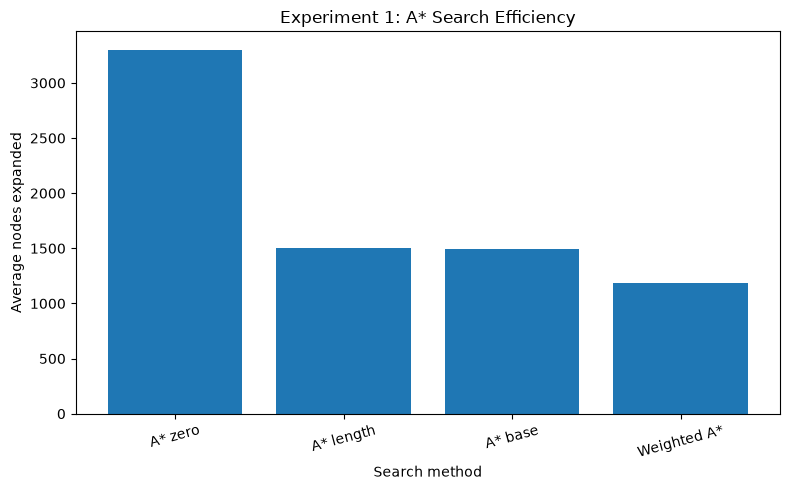

Base-count vs zero reduction: 54.72 %
Weighted vs base-count reduction: 20.71 %
Weighted A* non-optimal results: 145


In [16]:
# --- VISUALISATION 1 ---

plt.figure(figsize=(8, 5))
plt.bar(methods, average_nodes)

plt.title("Experiment 1: A* Search Efficiency")
plt.xlabel("Search method")
plt.ylabel("Average nodes expanded")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Percentage reductions
base_reduction = (average_nodes[0] - average_nodes[2]) / average_nodes[0] * 100
weighted_reduction = (average_nodes[2] - average_nodes[3]) / average_nodes[2] * 100

print("Base-count vs zero reduction:", round(base_reduction, 2), "%")
print("Weighted vs base-count reduction:", round(weighted_reduction, 2), "%")
print("Weighted A* non-optimal results:", len(failures))

# --- END YOUR CODE ---

### Visualisation 1: Results and Analysis

Figure 1 shows that zero A* expanded the most nodes, averaging 3,302, while Weighted A* expanded the fewest, averaging 1,185. The base-count heuristic reduced node expansions by 54% compared with zero A*.

For my H1 target of 60- and 100-base sequences with 15% mixed mutations, base-count A* reduced node expansions by 54.82% for generation B and 54.93% for generation C. The combined reduction was 54.88%, exceeding my target of 15%.

All three standard A* methods returned the correct minimum edit distance in all 2,700 comparisons. Weighted A* was more efficient in terms of nodes expanded, but returned a higher cost in 145 comparisons (5.37%). When it failed, the cost was on average 1.06 edits higher than the correct distance, with a maximum difference of 2 edits.

Interestingly, Weighted A* failed similarly for generation B (5.26%) and generation C (5.48%). Failures were also more common for longer sequences, increasing from 3.56% for 30-base DNA to 6.22% for 100-base DNA. This shows that Weighted A* does not always find the optimal result, although its errors were relatively small in this experiment.

For runtime, zero A* averaged 7.4 ms, length A* 4 ms, base-count A* 4.9 ms and Weighted A* 4.2 ms. Although base-count expanded slightly fewer nodes than length A*, it took longer, possibly because its heuristic requires more calculations. Runtime includes suffix-count preprocessing, search and alignment reconstruction, but excludes data generation and Levenshtein verification.

Overall, the experiment shows that heuristics can greatly reduce search effort. Standard A* preserves the minimum edit cost, while Weighted A* trades guaranteed optimality for fewer expanded nodes.

### Experiment 2

In this experiment, I test how accurately A* identifies the original DNA sequence across three simulated generations of bacteria.

Set A contains the original references. Set B contains sequences after one round of mutations, and Set C contains sequences after two rounds.

I combine and shuffle the samples from B and C. For each sample, I use standard A* with the base-count heuristic to calculate its edit distance against all five references in Set A. I select the reference with the lowest cost and compare its index with the sample's stored origin.

I then compare matching accuracy across generations, DNA lengths, mutation rates and mutation types. I also check whether any references have the same minimum edit cost, making the prediction ambiguous.

In [17]:
# --- EXPERIMENT 2 ---

# --- YOUR CODE HERE ---

# Identify original DNA sequences

matching_results = []

for trial in trials:
    for sample in trial["samples"]:
        costs = []

        # Compare each B or C sample with all five original references
        for reference in trial["references"]:
            answer = a_star(reference, sample["dna"], "base")
            costs.append(answer["cost"])

        # Predict the original reference with the smallest edit cost
        best_cost = min(costs)
        predicted = costs.index(best_cost)

        matching_results.append({
            "generation": sample["generation"],
            "length": trial["length"],
            "rate": trial["rate"],
            "kind": trial["kind"],
            "origin": sample["origin"],
            "predicted": predicted,
            "correct": predicted == sample["origin"],
            "tie": costs.count(best_cost) > 1,
            "costs": costs
        })

# Overall results
correct = sum(r["correct"] for r in matching_results)
ties = sum(r["tie"] for r in matching_results)

print("Total samples:", len(matching_results))
print("Correct matches:", correct)
print("Overall accuracy:", round(correct / len(matching_results) * 100, 2), "%")
print("Ambiguous matches:", ties)

print("\nAccuracy by generation:")

for generation in ["B", "C"]:
    group = [r for r in matching_results if r["generation"] == generation]
    matches = sum(r["correct"] for r in group)

    print("Generation", generation, ":", matches, "/", len(group),
          "| Accuracy:", round(matches / len(group) * 100, 2), "%")

print("\nAccuracy by DNA length:")

for length in [30, 60, 100]:
    group = [r for r in matching_results if r["length"] == length]
    matches = sum(r["correct"] for r in group)

    print(length, "bases:", matches, "/", len(group),
          "| Accuracy:", round(matches / len(group) * 100, 2), "%")

print("\nAccuracy by mutation type:")

for kind in ["substitution", "mixed"]:
    group = [r for r in matching_results if r["kind"] == kind]
    matches = sum(r["correct"] for r in group)

    print(kind, ":", matches, "/", len(group),
          "| Accuracy:", round(matches / len(group) * 100, 2), "%")

unique_correct = sum(r["correct"] and not r["tie"] for r in matching_results)
print("Correct matches without ties:", unique_correct)

# --- END YOUR CODE ---

Total samples: 540
Correct matches: 538
Overall accuracy: 99.63 %
Ambiguous matches: 2

Accuracy by generation:
Generation B : 270 / 270 | Accuracy: 100.0 %
Generation C : 268 / 270 | Accuracy: 99.26 %

Accuracy by DNA length:
30 bases: 178 / 180 | Accuracy: 98.89 %
60 bases: 180 / 180 | Accuracy: 100.0 %
100 bases: 180 / 180 | Accuracy: 100.0 %

Accuracy by mutation type:
substitution : 268 / 270 | Accuracy: 99.26 %
mixed : 270 / 270 | Accuracy: 100.0 %
Correct matches without ties: 537


In [18]:
# Show how one DNA sample was matched

trial = trials[0]
sample = trial["samples"][0]

print("Generation:", sample["generation"])
print("Modified DNA:", sample["dna"])
print("Actual origin:", sample["origin"])

print("\nEdit costs against the five references:")

for i in range(5):
    answer = a_star(trial["references"][i], sample["dna"], "base")
    print("Reference", i, ":", answer["cost"])

print("\nPredicted origin:", matching_results[0]["predicted"])


# Look at incorrect or ambiguous predictions
print("\nIncorrect or ambiguous matches:")

for result in matching_results:
    if not result["correct"] or result["tie"]:
        print("Generation:", result["generation"],
              "| Length:", result["length"],
              "| Rate:", result["rate"],
              "| Type:", result["kind"])
        print("Actual:", result["origin"],
              "| Predicted:", result["predicted"],
              "| Costs:", result["costs"],
              "| Tie:", result["tie"])
        print()


Generation: B
Modified DNA: GTCACTAAATACTTTAACCAA
TATGGGCA
Actual origin: 4

Edit costs against the five references:
Reference 0 : 19
Reference 1 : 16
Reference 2 : 18
Reference 3 : 17
Reference 4 : 1

Predicted origin: 4

Incorrect or ambiguous matches:
Generation: C | Length: 30 | Rate: 0.3 | Type: substitution
Actual: 0 | Predicted: 1 | Costs: [17, 16, 16, 20, 18] | Tie: True

Generation: C | Length: 30 | Rate: 0.3 | Type: substitution
Actual: 0 | Predicted: 2 | Costs: [18, 20, 17, 19, 19] | Tie: False

Generation: C | Length: 30 | Rate: 0.3 | Type: substitution
Actual: 0 | Predicted: 0 | Costs: [15, 18, 15, 18, 23] | Tie: True



### Visualisation 2

Generation: B | Mutation rate: 5.0 % | Accuracy: 100.0 %
Generation: B | Mutation rate: 15.0 % | Accuracy: 100.0 %
Generation: B | Mutation rate: 30.0 % | Accuracy: 100.0 %
Generation: C | Mutation rate: 5.0 % | Accuracy: 100.0 %
Generation: C | Mutation rate: 15.0 % | Accuracy: 100.0 %
Generation: C | Mutation rate: 30.0 % | Accuracy: 97.78 %


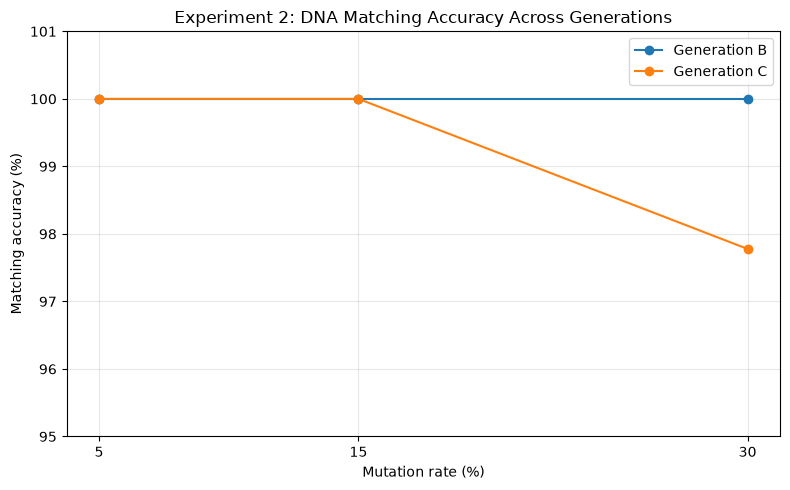

In [19]:

# --- VISUALISATION 2 ---

rates = [0.05, 0.15, 0.30]

plt.figure(figsize=(8, 5))

for generation in ["B", "C"]:
    accuracies = []

    for rate in rates:
        total = 0
        correct = 0

        for result in matching_results:
            if (result["generation"] == generation
                and result["rate"] == rate):

                total += 1

                if result["correct"]:
                    correct += 1

        accuracy = correct / total * 100
        accuracies.append(accuracy)

        print("Generation:", generation,
              "| Mutation rate:", rate * 100, "%",
              "| Accuracy:", round(accuracy, 2), "%")

    plt.plot([5, 15, 30], accuracies, marker="o",
             label="Generation " + generation)

plt.title("Experiment 2: DNA Matching Accuracy Across Generations")
plt.xlabel("Mutation rate (%)")
plt.ylabel("Matching accuracy (%)")
plt.xticks([5, 15, 30])
plt.ylim(95, 101)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- END YOUR CODE ---

### Visualisation 2: Results and Analysis

Figure 2 compares DNA matching accuracy for generations B and C across three mutation rates.

Generation B achieved 100% accuracy at all three rates. Generation C also achieved 100% accuracy at 5% and 15%, but decreased to 97% at 30%.

Overall, A* correctly identified 538 out of 540 samples (99%). There were three ambiguous predictions, all involving 30-base sequences from generation C with 30% substitution mutations.

I expected the third generation to be harder to match because it had undergone two rounds of mutations. The results show a small decrease in accuracy, but only two incorrect predictions, so I cannot conclude that this will always happen.

An important finding is that A* can calculate the correct minimum edit distance without identifying the correct original source. After enough changes, a DNA sequence may become closer to another reference than to the one it came from.

The results meet my H1 accuracy target of 80%, but more challenging reference sequences and additional trials would be needed to test how reliable the method is.

---

## H2.2: Project Report (~1500 words)

### 1. Problem Definition and Motivation (~200 words)

What problem did you solve? Why does it matter? Why is AI the right approach? (Build on H1; don't just paste it.)

* My project uses A* search to match bacterial DNA sequences across three simulated generations.

I start with five original DNA fragments from E. coli, called Set A. These represent the first generation. I introduce mutations to create Set B, representing the second generation, then mutate Set B again to create Set C, representing the third generation.

I combine and shuffle samples from B and C. My program compares each sample with the five original sequences in Set A and predicts which original it came from.

To compare two DNA sequences, I use Levenshtein edit distance. This is the minimum number of insertions, deletions and substitutions needed to change one sequence into another. Matching bases cost 0, while each edit costs 1. Insertions and deletions make simple position-by-position comparison unsuitable because they shift the remaining bases.

The problem is interesting because differences can accumulate between a DNA sequence and its earlier version. I want to see whether the original sequence can still be identified after one or two rounds of mutations.

I chose A* because DNA alignment involves searching through different possible sequences of edits. A* uses the cost already incurred and an estimate of the remaining cost to decide which states to explore first.

My main aim is to compare A* heuristics, investigate Weighted A* and test how accurately edit distance can identify the original DNA. This is a simplified simulation of genetic changes, not a tool for proving real bacterial ancestry.
*

### 2. Technical Approach (~300 words)

What technique(s) did you use? How did you adapt or extend them? What design decisions did you make and why?

*I used 45 DNA fragments from the E. coli K-12 MG1655 reference genome (NCBI accession NC_000913.3). I extracted consecutive, non-overlapping fragments of lengths 30, 60 and 100 bases. For each length, I created three subgroups of five original sequences.

These form Set A. I wrote mutate_sequence() to randomly change DNA bases according to a mutation rate. I tested substitution-only mutations and mixed mutations containing substitutions, insertions and deletions.

For each reference, I first create a Set B sequence, then mutate that sequence again to create Set C. Each sample keeps its original Set A index and a label indicating whether it belongs to B or C.

I use mutation rates of 5%, 15% and 30%, producing 54 trials across the different sequence lengths, mutation types and subgroups. Each trial contains five references and ten modified samples. This requires 50 DNA comparisons per trial, or 2,700 comparisons per search method. I use a random seed of 42 to make the generated data reproducible.

I adapted the A* structure from my D1 8-puzzle task, reusing PriorityQueue and _reconstruct from d1_helpers.py.

For DNA matching, a state (i, j) represents how many bases have been processed from each sequence. Moving diagonally represents a match or substitution, while moving only one index represents an insertion or deletion.

I also wrote make_alignment() to display the path found by A* using gaps where necessary.

I implemented three heuristics: zero, remaining-length difference and base-count difference. The base-count heuristic compares the remaining numbers of A, T, C and G bases. I use suffix_counts() to calculate these counts in advance rather than recounting them at every search state.

Standard A* uses g + h, while Weighted A* uses g + 1.5h. Weighted A* gives more importance to the estimated remaining cost and may find a non-optimal path.

I use the Python Levenshtein library to verify exact minimum edit distances. I also test normal and tricky DNA pairs, checking edit costs, alignment reconstruction and the cost represented by the alignment.

For runtime, I use time.perf_counter() starting before suffix-count preprocessing. The measurement includes preprocessing, search and alignment reconstruction, but excludes data generation and independent Levenshtein verification.
*

### 3. Results and Analysis (~400 words)

What worked? What didn't? Reference your visualisations. How does performance change across experiments? Surprising findings?

*Experiment 1: Search Efficiency and Correctness

My first experiment compares standard A* using three heuristics with Weighted A* on the same 2,700 DNA pairs.

All three standard A* methods returned the exact Levenshtein distance for every comparison.

Figure 1 compares average nodes expanded. Zero A* expanded 3,302 nodes on average, length A* expanded 1,499, base-count A* expanded 1,495, and Weighted A* expanded 1,185

Base-count A* reduced expansions by 54% compared with zero A*. For my H1 target group of 60- and 100-base sequences with 15% mixed mutations, the combined reduction was 54%, exceeding my target of 15%.

However, base-count A* was not the fastest method. Its average runtime was 4.9ms, compared with 4ms for length A*. Zero A* averaged 7.4 ms, while Weighted A* averaged 4.2 ms.

This shows that fewer node expansions do not always mean lower runtime. The base-count heuristic performs more calculations, which may explain why it was slightly slower than length A*.

Weighted A* explored 20% fewer nodes than standard base-count A*. However, it returned a non-optimal edit cost in 145 out of 2,700 comparisons (5%). The returned cost was an average of 1.06 edits too high in these failures, with the largest difference being 2 edits.

An unexpected result was that generation B had almost same Weighted A* failures than generation C: 5.26% compared with 5.48%. I expected generaton C to give more failures as it had undergone twice the number of mutations. 

This does not mean that less mutated DNA will be harder. Each modified sample was compared with all five references, including four that were not its actual source. Weighted A* failures depend on the alignment paths and heuristic choices, not simply the number of mutations.

Failures also increased with DNA length, from 3.5% for 30-base sequences to 6.2% for 100-base sequences.

These findings show the trade-off between search efficiency and optimality. Weighted A* explored fewer states, but did not always return the minimum edit cost.

Experiment 2: DNA Matching Accuracy

My second experiment tests whether standard A* can identify the original Set A sequence for samples from generations B and C.

Each sample is compared with all five references. I select the reference with the lowest edit cost and compare it with the sample's stored origin.

Across 540 modified samples, 538 were correctly matched, giving an overall accuracy of 99.63%.

Generation B achieved 100% accuracy, with all 270 samples matched correctly. Generation C achieved 99.26% accuracy, with 268 out of 270 correct.

Figure 2 compares matching accuracy against mutation rate for both generations. Generation B remained at 100% across all mutation rates. Generation C also achieved 100% at 5% and 15%, but decreased to 97% at 30%.

There were three ambiguous predictions, all involving 30-base, third-generation sequences with 30% substitution-only mutations.

One third-generation sample was incorrectly assigned to another original reference. Its actual source was reference 0, with an edit cost of 17, but references 1 and 2 both had smaller costs of 16.

This is an important finding because A* calculated the edit distances correctly. The incorrect prediction happened because the modified sample had become closer to other references than to its true original.

The results exceeded my H1 matching accuracy target of 80%. However, one of the correct predictions also involved tied minimum costs, meaning they were not uniquely identified.

Overall, the experiment suggests that A* can match these simulated DNA sequences accurately, but the closest sequence is not always the true original source.
*

### 4. Limitations and Future Work (~200 words)

Where does your approach fail? What assumptions are violated? What would you do with more time? Be specific.

*One limitation is that the dataset comes from a single bacterial reference genome. The original DNA is real, but the second and third generations are artificially generated. They do not model complete bacterial reproduction or real evolutionary processes.

Another limitation is that the five references in each group are generally quite different. This made most modified samples easy to identify, even after two rounds of mutations.

In future, I would test overlapping or deliberately similar references. This would make it harder to distinguish the original sources and allow me to investigate more incorrect or ambiguous predictions.

I would also run the experiment with different random seeds. Using one seed makes the results reproducible, but does not show how much matching accuracy or Weighted A* performance might vary between datasets.

My implementation gives all insertions, deletions and substitutions the same cost. Real biological mutations may have different frequencies and effects, which my model does not represent.

The current matching rule selects the first reference when several references share the smallest cost. Although I record ties, a better version would report all equally close references instead of making a single confident prediction.

Finally, I would compare A* against a dynamic-programming alignment algorithm on longer DNA sequences with higher mutations to study time and memory usage and check whether accuracy falls.
*

### 5. Ethical Reflection (~200 words)

If deployed, who is affected? What failure modes matter most? Connect to at least one concept from C2 (Classification & Fairness) or C4 (Deployment & Model Cards).

*My project uses simulated bacterial DNA generations, so it does not directly involve private genetic information from people. However, responsible use is still important if a similar approach were applied to biological research.

The main risk is treating the closest DNA sequence as definite proof of its origin.

This connects to C4's ideas about responsible deployment and model cards. Users should understand what a system was designed to do, what data it was tested on and where its predictions may be unreliable.

My experiment achieved 99% accuracy, but this result came from a controlled simulation using only five references per trial. Reporting the percentage without explaining these conditions could make the method seem more reliable than it actually is.

The incorrect third-generation prediction demonstrates this limitation. Even when the edit distances are correct, the original source can be identified incorrectly.

If this system were used by researchers, I would display the closest edit distances, highlight ties and allow users to inspect the DNA alignments. I would also state clearly that the method measures sequence similarity rather than proving biological ancestry.

If extended to human DNA, privacy, consent and secure management of genetic information would become important additional concerns.*

### 6. AI Use Statement (~100 words)

How did you use AI tools? What did you accept? What did you reject, and why?

*I didnt use AI in this *

---

## Submission Checklist

- [ Y] Recap of H1 scope (and any pivot) at the top
- [Y ] Working notebook with data, implementation, 2+ experiments, 2+ visualisations
- [ Y] Project report (~1500 words) covering all 6 sections
- [Y ] Implementation demonstrates HD-level depth beyond earlier task work
- [Y ] Ethical reflection connects to C2 or C4
- [Y ] AI use statement shows critical evaluation
- [ Y] Code is readable, reproducible, documented
- [ ] Uploaded to OnTrack and marked **Ready for Feedback**
- [ ] H3 interview booking confirmed for W14

---

*FIT1061 HD Task H2: Comprehensive Project: Implementation & Review*